Libraries loaded
cars -> (1217, 14) | target balance: {0: 609, 1: 608}
netflix -> (8807, 19) | target balance: {1: 6131, 0: 2676}
CAR PRICE CLASS
               precision    recall  f1-score   support

Not expensive       0.87      0.89      0.88       122
    Expensive       0.89      0.87      0.88       122

     accuracy                           0.88       244
    macro avg       0.88      0.88      0.88       244
 weighted avg       0.88      0.88      0.88       244



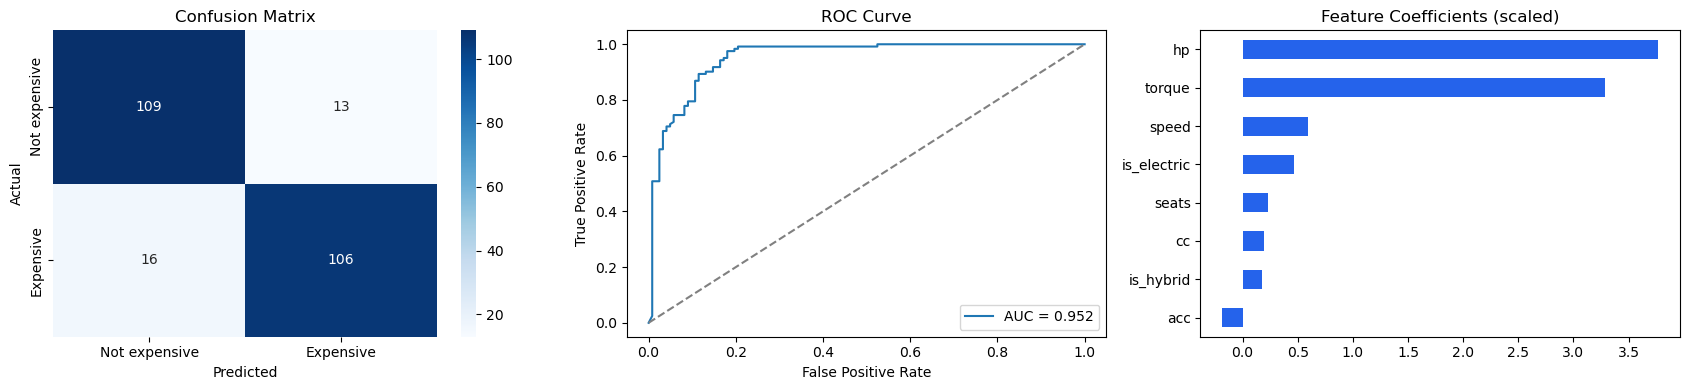

NETFLIX: MOVIE OR TV SHOW
              precision    recall  f1-score   support

     TV Show       0.94      0.90      0.92       535
       Movie       0.96      0.97      0.97      1227

    accuracy                           0.95      1762
   macro avg       0.95      0.94      0.94      1762
weighted avg       0.95      0.95      0.95      1762



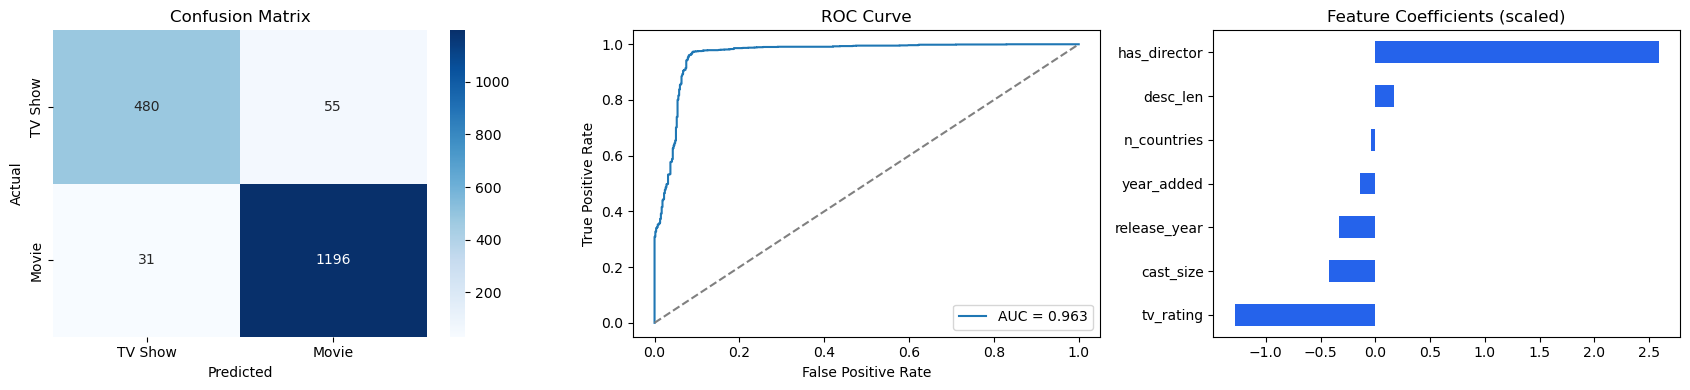

,Accuracy,Precision,Recall,F1,ROC_AUC
Car Price Class,0.881,0.891,0.869,0.880,0.952
Netflix: Movie or TV Show,0.951,0.956,0.975,0.965,0.963


cars ('Not expensive', 0.36767316885676726)
netflix ('Movie', 0.9470819767238992)
* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Flask running at http://127.0.0.1:5000


In [2]:
import re, threading
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,                             
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
import gradio as gr
from flask import Flask, request, render_template_string
from werkzeug.serving import make_server

print("Libraries loaded")

# -------------------------------------------------------------
# Load and prepare both datasets
# -------------------------------------------------------------
CARS_CSV = r"D:\archive (2)\Cars Datasets 2025.csv"
NETFLIX_CSV = r"D:\archive (3)\netflix_titles.csv"

def first_num(x):
    nums = re.findall(r"\d+\.?\d*", str(x).replace(",", ""))
    return float(np.mean([float(n) for n in nums])) if nums else np.nan

# Dataset 1: Cars
cars = pd.read_csv(CARS_CSV, encoding="latin-1")
cars.columns = ["company", "car", "engine", "cc", "hp", "speed", "acc", "price", "fuel", "seats", "torque"]
for c in ["cc", "hp", "speed", "acc", "price", "seats", "torque"]:
    cars[c] = cars[c].apply(first_num)
cars = cars.dropna(subset=["price"]).copy()
cars["expensive"] = (cars["price"] > cars["price"].median()).astype(int)
cars["is_electric"] = cars["fuel"].fillna("").str.contains("electric", case=False).astype(int)
cars["is_hybrid"] = cars["fuel"].fillna("").str.contains("hybrid|hyrbrid", case=False).astype(int)

# Dataset 2: Netflix
nf = pd.read_csv(NETFLIX_CSV)
nf["is_movie"] = (nf["type"] == "Movie").astype(int)
nf["year_added"] = pd.to_datetime(nf["date_added"].str.strip(), errors="coerce").dt.year
nf["has_director"] = nf["director"].notna().astype(int)
nf["cast_size"] = nf["cast"].fillna("").apply(lambda s: len([p for p in s.split(",") if p.strip()]))
nf["n_countries"] = nf["country"].fillna("").apply(lambda s: len([p for p in s.split(",") if p.strip()]))
nf["desc_len"] = nf["description"].fillna("").str.len()
nf["tv_rating"] = nf["rating"].fillna("").str.startswith("TV").astype(int)

DATASETS = {
    "cars": dict(
        title="Car Price Class",
        df=cars,
        features=["cc", "hp", "speed", "acc", "seats", "torque", "is_electric", "is_hybrid"],
        target="expensive",
        labels={0: "Not expensive", 1: "Expensive"},
    ),
    "netflix": dict(
        title="Netflix: Movie or TV Show",
        df=nf,
        features=["release_year", "year_added", "has_director", "cast_size", "n_countries", "desc_len", "tv_rating"],
        target="is_movie",
        labels={0: "TV Show", 1: "Movie"},
    ),
}

for k, c in DATASETS.items():
    c["defaults"] = {f: round(float(c["df"][f].median()), 2) for f in c["features"]}
    print(k, "->", c["df"].shape, "| target balance:", c["df"][c["target"]].value_counts().to_dict())

# -------------------------------------------------------------
# Train both models and show results
# -------------------------------------------------------------
MODELS, RESULTS = {}, {}
for key, cfg in DATASETS.items():
    X = cfg["df"][cfg["features"]]
    y = cfg["df"][cfg["target"]]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000)),
    ])
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    
    MODELS[key] = model
    RESULTS[key] = dict(
        Accuracy=accuracy_score(y_te, pred), 
        Precision=precision_score(y_te, pred),
        Recall=recall_score(y_te, pred), 
        F1=f1_score(y_te, pred), 
        ROC_AUC=roc_auc_score(y_te, proba)
    )
    
    print("=" * 60)
    print(cfg["title"].upper())
    print("=" * 60)
    print(classification_report(y_te, pred, target_names=[cfg["labels"][0], cfg["labels"][1]]))
    
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    sns.heatmap(confusion_matrix(y_te, pred), annot=True, fmt="d", cmap="Blues", ax=ax[0],
                xticklabels=[cfg["labels"][0], cfg["labels"][1]], yticklabels=[cfg["labels"][0], cfg["labels"][1]])
    ax[0].set_title("Confusion Matrix"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
    
    fpr, tpr, _ = roc_curve(y_te, proba)
    ax[1].plot(fpr, tpr, label=f"AUC = {RESULTS[key]['ROC_AUC']:.3f}")
    ax[1].plot([0, 1], [0, 1], "--", color="gray")
    ax[1].set_title("ROC Curve"); ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate"); ax[1].legend()
    
    coefs = pd.Series(model.named_steps["clf"].coef_[0], index=cfg["features"]).sort_values()
    coefs.plot(kind="barh", ax=ax[2], color="#2563eb")
    ax[2].set_title("Feature Coefficients (scaled)")
    plt.tight_layout(); plt.show()

# -------------------------------------------------------------
# Comparison table
# -------------------------------------------------------------
comparison = pd.DataFrame(RESULTS).T.round(3)
comparison.index = [DATASETS[k]["title"] for k in comparison.index]
display(comparison)

# -------------------------------------------------------------
# Prediction function & testing defaults
# -------------------------------------------------------------
def predict(key, values):
    cfg = DATASETS[key]
    row = pd.DataFrame([values], columns=cfg["features"])
    p = float(MODELS[key].predict_proba(row)[0][1])
    return cfg["labels"][int(p >= 0.5)], p

for k, c in DATASETS.items():
    print(k, predict(k, [c["defaults"][f] for f in c["features"]]))

# -------------------------------------------------------------
# Gradio UI
# -------------------------------------------------------------
def make_tab(key):
    cfg = DATASETS[key]
    def fn(*vals):
        label, p = predict(key, list(vals))
        return {cfg["labels"][1]: p, cfg["labels"][0]: 1 - p}
    return gr.Interface(
        fn=fn,
        inputs=[gr.Number(value=cfg["defaults"][f], label=f) for f in cfg["features"]],
        outputs=gr.Label(label="Prediction"),
        title=cfg["title"],
    )

demo = gr.TabbedInterface([make_tab(k) for k in DATASETS], [DATASETS[k]["title"] for k in DATASETS])
demo.launch(share=False)

# -------------------------------------------------------------
# Flask UI
# -------------------------------------------------------------
PAGE = """<!doctype html><html><head><meta charset="utf-8"><title>Logistic Regression Classifier</title><style> body{font-family:system-ui,sans-serif;max-width:640px;margin:2rem auto;padding:0 1rem} nav a{margin-right:1rem} label{display:block;margin-top:.7rem;font-size:.9rem} input{width:100%;padding:.4rem;box-sizing:border-box} button{margin-top:1rem;padding:.6rem 1.2rem;background:#2563eb;color:#fff;border:0;border-radius:6px} .result{margin-top:1.5rem;padding:1rem;background:#eef2ff;border-radius:8px}</style></head><body><nav><a href="/">Home</a>{% for k,c in datasets.items() %}<a href="/{{k}}">{{c.title}}</a>{% endfor %}</nav>{% if key %}  <h2>{{datasets[key].title}}</h2>  <form method="post">    {% for f in datasets[key].features %}      <label>{{f}}<input type="number" step="any" name="{{f}}" value="{{values[f]}}" required></label>    {% endfor %}    <button type="submit">Predict</button>  </form>  {% if result %}<div class="result"><b>Prediction:</b> {{result.label}}<br>  <b>Probability of {{datasets[key].labels[1]}}:</b> {{result.prob}}%</div>{% endif %}{% else %}  <h1>Logistic Regression: Two Datasets</h1>  <ul>{% for k,c in datasets.items() %}<li><a href="/{{k}}">{{c.title}}</a></li>{% endfor %}</ul>{% endif %}</body></html>"""

app = Flask(__name__)

@app.route("/")
def home():
    return render_template_string(PAGE, datasets=DATASETS, key=None)

@app.route("/<key>", methods=["GET", "POST"])
def form(key):
    if key not in DATASETS:
        return "Unknown dataset", 404
    cfg = DATASETS[key]
    values, result = dict(cfg["defaults"]), None
    if request.method == "POST":
        values = {f: float(request.form[f]) for f in cfg["features"]}
        label, p = predict(key, [values[f] for f in cfg["features"]])
        result = {"label": label, "prob": round(p * 100, 1)}
    return render_template_string(PAGE, datasets=DATASETS, key=key, values=values, result=result)

try:
    server.shutdown()
except NameError:
    pass

server = make_server("127.0.0.1", 5000, app)
threading.Thread(target=server.serve_forever, daemon=True).start()
print("Flask running at http://127.0.0.1:5000")